# Random Forest Classification

This notebook uses the cleaned credit card default dataset to evaluate a Random Forest classifier and examine feature importance. It is separated from the data-cleaning notebook so the model can be run and reviewed independently.


## 1. Import Libraries, Load Cleaned Data, and Prepare Train/Test Sets


In [2]:
# Upload the cleaned dataset.
from google.colab import files

uploaded = files.upload()

# Load the cleaned dataset.
df = pd.read_csv("cleaned_credit_card_data.csv")

Saving cleaned_credit_card_data.csv to cleaned_credit_card_data.csv


In [3]:
# Import libraries.
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

# Load the cleaned dataset exported from the EDA notebook.
#df = pd.read_csv("cleaned_credit_card_data.csv")

# Separate predictors and target variable.
X = df.drop(columns=["DEFAULT"])
y = df["DEFAULT"]

# Create the same 80/20 stratified split used in the combined notebook.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

categorical_features = [
    "SEX",
    "EDUCATION",
    "MARRIAGE"
]

numeric_features = [
    column for column in X.columns
    if column not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

print(f"Training Observations: {X_train.shape[0]:,}")
print(f"Testing Observations: {X_test.shape[0]:,}")
print(f"Training Default Rate: {y_train.mean() * 100:.2f}%")
print(f"Testing Default Rate: {y_test.mean() * 100:.2f}%")


Training Observations: 24,000
Testing Observations: 6,000
Training Default Rate: 22.12%
Testing Default Rate: 22.12%


## 2. Baseline Classification


In [4]:
# Create a baseline classifier for comparison.
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]
)

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)
baseline_probabilities = baseline_model.predict_proba(X_test)[:, 1]

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_precision = precision_score(
    y_test, baseline_predictions, zero_division=0
)
baseline_recall = recall_score(
    y_test, baseline_predictions, zero_division=0
)
baseline_f1 = f1_score(
    y_test, baseline_predictions, zero_division=0
)
baseline_auc = roc_auc_score(y_test, baseline_probabilities)

print(f"Baseline Accuracy: {baseline_accuracy:.4f}")
print(f"Baseline Precision: {baseline_precision:.4f}")
print(f"Baseline Recall: {baseline_recall:.4f}")
print(f"Baseline F1 Score: {baseline_f1:.4f}")
print(f"Baseline ROC-AUC: {baseline_auc:.4f}")


Baseline Accuracy: 0.7788
Baseline Precision: 0.0000
Baseline Recall: 0.0000
Baseline F1 Score: 0.0000
Baseline ROC-AUC: 0.5000


## 3. Random Forest Classification


In [5]:
from sklearn.ensemble import RandomForestClassifier

# Create and train the Random Forest model.
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                min_samples_leaf=5,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

random_forest_predictions = random_forest_model.predict(X_test)
random_forest_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

random_forest_accuracy = accuracy_score(
    y_test, random_forest_predictions
)
random_forest_precision = precision_score(
    y_test, random_forest_predictions, zero_division=0
)
random_forest_recall = recall_score(
    y_test, random_forest_predictions, zero_division=0
)
random_forest_f1 = f1_score(
    y_test, random_forest_predictions, zero_division=0
)
random_forest_auc = roc_auc_score(
    y_test, random_forest_probabilities
)

print(f"Random Forest Accuracy: {random_forest_accuracy:.4f}")
print(f"Random Forest Precision: {random_forest_precision:.4f}")
print(f"Random Forest Recall: {random_forest_recall:.4f}")
print(f"Random Forest F1 Score: {random_forest_f1:.4f}")
print(f"Random Forest ROC-AUC: {random_forest_auc:.4f}")

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(y_test, random_forest_predictions))


Random Forest Accuracy: 0.8017
Random Forest Precision: 0.5548
Random Forest Recall: 0.5222
Random Forest F1 Score: 0.5380
Random Forest ROC-AUC: 0.7721

Random Forest Confusion Matrix:
[[4117  556]
 [ 634  693]]


### Random Forest Interpretation

Using the saved results from the original combined notebook, Random Forest achieved an accuracy of **80.17%**, precision of **55.48%**, recall of **52.22%**, F1 score of **53.80%**, and ROC-AUC of **0.7721**. Among the models in the combined notebook, it had the strongest overall accuracy, precision, F1 score, and ROC-AUC.


## 4. Model Comparison


In [6]:
model_comparison = pd.DataFrame({
    "Model": ["Baseline", "Random Forest"],
    "Accuracy": [baseline_accuracy, random_forest_accuracy],
    "Precision": [baseline_precision, random_forest_precision],
    "Recall": [baseline_recall, random_forest_recall],
    "F1 Score": [baseline_f1, random_forest_f1],
    "ROC-AUC": [baseline_auc, random_forest_auc]
})

model_comparison[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
] = model_comparison[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].round(4)

model_comparison


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline,0.7788,0.0000,0.0000,0.000,0.5000
1,Random Forest,0.8017,0.5548,0.5222,0.538,0.7721


## 5. Random Forest Feature Importance


In [7]:
# Access the fitted preprocessing step and Random Forest classifier.
fitted_preprocessor = random_forest_model.named_steps["preprocessor"]
fitted_random_forest = random_forest_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
feature_importance_values = fitted_random_forest.feature_importances_

feature_importance_table = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance_values
})

feature_importance_table["Feature"] = (
    feature_importance_table["Feature"]
    .str.replace("categorical__", "", regex=False)
    .str.replace("numeric__", "", regex=False)
)

feature_importance_table = (
    feature_importance_table
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

feature_importance_table.head(15)


,Feature,Importance
0,PAY_0,0.140755
1,BILL_AMT1,0.055077
2,LIMIT_BAL,0.054939
3,PAY_2,0.054769
4,PAY_AMT1,0.051249
5,PAY_AMT2,0.049430
6,BILL_AMT2,0.047449
7,PAY_AMT3,0.046602
8,BILL_AMT4,0.044189
9,BILL_AMT3,0.043434


### Feature Importance Interpretation

The saved results from the original combined notebook ranked **PAY_0** as the strongest predictor, followed by variables including **BILL_AMT1**, **LIMIT_BAL**, **PAY_2**, and **PAY_AMT1**.


## 6. Visualize Most Important Predictors


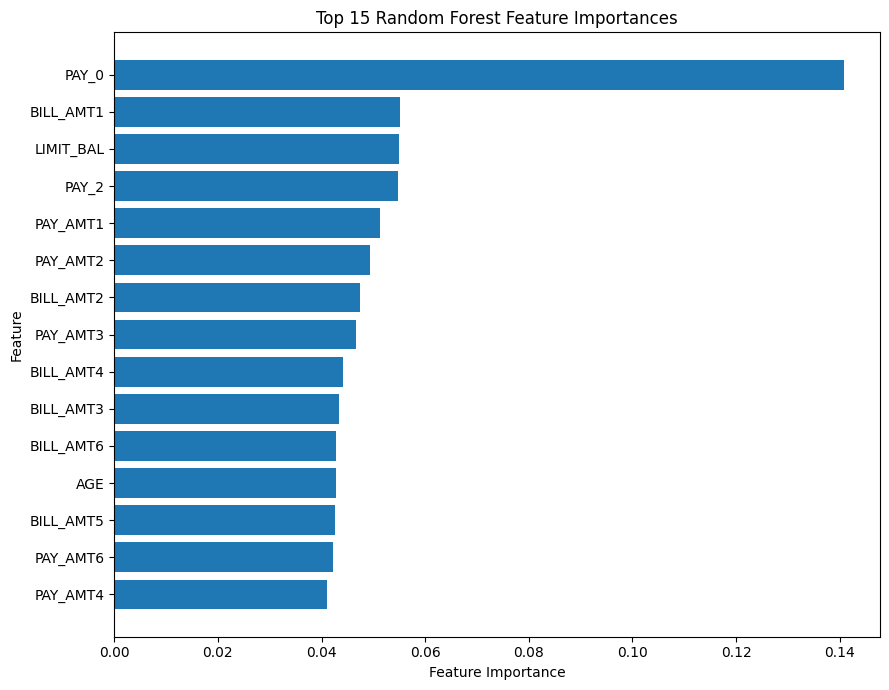

In [8]:
top_features = (
    feature_importance_table
    .head(15)
    .sort_values("Importance", ascending=True)
)

plt.figure(figsize=(9, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
